# Creditworthiness modelling: Baselines

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text, plot_tree
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, 
                            classification_report, confusion_matrix, 
                            ConfusionMatrixDisplay)

<h2 style="color:orange">Load the data and split</h2>

In [41]:
# load data
path = "../data/processed-data/processed_data.csv"
df = pd.read_csv(path)

In [42]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32574 entries, 0 to 32573
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_age_years                  32574 non-null  int64  
 1   person_home_ownership             32574 non-null  str    
 2   person_emp_length_years           31679 non-null  float64
 3   loan_intent                       32574 non-null  str    
 4   loan_grade                        32574 non-null  str    
 5   loan_int_rate                     29459 non-null  float64
 6   loan_status                       32574 non-null  int64  
 7   cb_person_default_on_file         32574 non-null  int64  
 8   cb_person_cred_hist_length_years  32574 non-null  int64  
 9   loan_term_months                  32574 non-null  int64  
 10  loan_to_income_ratio              32574 non-null  float64
 11  open_accounts                     32574 non-null  int64  
 12  credit_utilizat

In [43]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [44]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## <font color="orange"> Dummy Classifiers </font>

In [45]:
dummy_clfs = {
    "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),
    "dummy_stratified": DummyClassifier(strategy="stratified", random_state=42),
    "dummy_constant": DummyClassifier(strategy="constant", constant=1),
}

In [46]:
for name, clf in dummy_clfs.items():
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    positive_idx = list(clf.classes_).index(1)
    y_score = clf.predict_proba(X_test)[:, positive_idx]

    print(f"\n{name}")
    print(f"Average precision: {average_precision_score(y_test, y_score):.4f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_test, y_score):.4f}")
    print(f"F1 score: {f1_score(y_test, y_pred, zero_division=0):.4f}")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))



dummy_most_frequent
Average precision: 0.2181
Balanced accuracy: 0.5000
ROC AUC: 0.5000
F1 score: 0.0000
              precision    recall  f1-score   support

           0      0.782     1.000     0.878      5094
           1      0.000     0.000     0.000      1421

    accuracy                          0.782      6515
   macro avg      0.391     0.500     0.439      6515
weighted avg      0.611     0.782     0.686      6515


dummy_stratified
Average precision: 0.2209
Balanced accuracy: 0.5078
ROC AUC: 0.5078
F1 score: 0.2295
              precision    recall  f1-score   support

           0      0.785     0.787     0.786      5094
           1      0.230     0.229     0.230      1421

    accuracy                          0.665      6515
   macro avg      0.508     0.508     0.508      6515
weighted avg      0.664     0.665     0.665      6515


dummy_constant
Average precision: 0.2181
Balanced accuracy: 0.5000
ROC AUC: 0.5000
F1 score: 0.3581
              precision    recall  f

## <font color="orange"> Pipelines for Decision Tree baseline </font>

In [47]:
# feature division 
binary_features = ["high_lti", "loan_grade_sep", "high_income", "high_lti_x_rent", "cb_person_default_on_file"]
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [ft for ft in numeric_features if ft not in binary_features]
ohe_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# impute pipeline
impute_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", KNNImputer(n_neighbors=5, weights="distance", add_indicator=True)), # default k=5
        ]), numeric_features),
        ("ohe", Pipeline([
            ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
        ]), ohe_features),
    ],
    remainder="passthrough", # nothing to do with binary features
)

# non-impute pipeline (using built-in)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("ohe", Pipeline([
            ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
        ]), ohe_features),
    ],
    remainder="passthrough", # nothing to do with binary features
)


In [48]:
# pipeline with kNN impute
impute_model = Pipeline([
    ("preprocessor", impute_preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5, 
                                        min_samples_leaf=20, 
                                        class_weight="balanced", 
                                        random_state=42)
    ),
])

impute_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['person_age_years','person_home_ownership','person_emp_length_years',..., 'high_lti_x_rent','log_person_income_usd','log_loan_amount_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dro

In [49]:
# pipeline without kNN impute
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5, 
                                        min_samples_leaf=20, 
                                        class_weight="balanced", 
                                        random_state=42)
    ),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['person_age_years','person_home_ownership','person_emp_length_years',..., 'high_lti_x_rent','log_person_income_usd','log_loan_amount_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dro

In [50]:
def ap_with_ci(y_true, proba, n_boot=1000, seed=42):
    """ helper to calculate average precision with 95% CI
    """
    y = np.asarray(y_true)
    p = np.asarray(proba)
    rng = np.random.default_rng(seed)
    scores = [
        average_precision_score(y[b], p[b])
        for b in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
    ]
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return average_precision_score(y, p), lo, hi

In [51]:
def report(clf_model):
    """ Helper to compute and report metrics """
    positive_idx = list(clf_model.classes_).index(1)
    rows = {}
    clf_reports = []
    for sname, X_s, y_s in [
        ("Training", X_train, y_train),
        ("Evaluation", X_test, y_test),
    ]:
        y_pred = clf_model.predict(X_s)   # threshold = 0.5
        score = clf_model.predict_proba(X_s)[:, positive_idx]
        rows[sname] = {
            "prevalence": np.mean(y_s),
            "PR-AUC (AP)": average_precision_score(y_s, score),
            "ROC-AUC": roc_auc_score(y_s, score),
            "balanced acc": balanced_accuracy_score(y_s, y_pred),
            "F1 (pos)": f1_score(y_s, y_pred, zero_division=0),
        }
        clf_reports.append(classification_report(y_s, y_pred, digits=3, zero_division=0))
        if sname == "Evaluation":
            ap, lo, hi = ap_with_ci(y_s, score)
            print(f"Test PR-AUC: {ap:.3f} [{lo:.3f}, {hi:.3f}]")
            print("Confusion matrix (rows = true, cols = predicted):")
            ConfusionMatrixDisplay.from_predictions(
                y_s, 
                y_pred, 
                cmap=plt.cm.Blues
            )
            plt.show()
    return rows, clf_reports

Test PR-AUC: 0.802 [0.785, 0.820]
Confusion matrix (rows = true, cols = predicted):


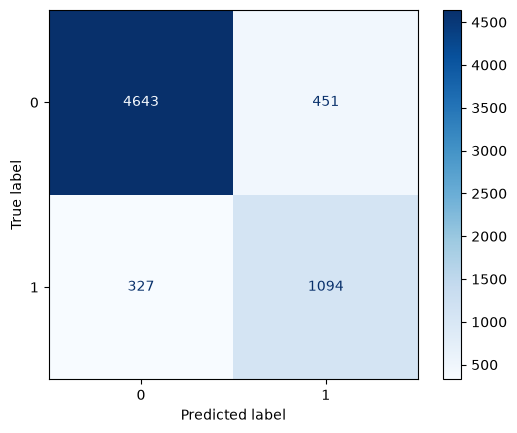

,prevalence,PR-AUC (AP),ROC-AUC,balanced acc,F1 (pos)
Training,0.2182,0.8167,0.8949,0.8507,0.7498
Evaluation,0.2181,0.8021,0.8796,0.8407,0.7377


Set train
              precision    recall  f1-score   support

           0      0.940     0.912     0.925     20373
           1      0.714     0.790     0.750      5686

    accuracy                          0.885     26059
   macro avg      0.827     0.851     0.838     26059
weighted avg      0.890     0.885     0.887     26059

Set test
              precision    recall  f1-score   support

           0      0.934     0.911     0.923      5094
           1      0.708     0.770     0.738      1421

    accuracy                          0.881      6515
   macro avg      0.821     0.841     0.830      6515
weighted avg      0.885     0.881     0.882      6515



In [52]:
# reports for impute_model
rows, rep = report(impute_model)
results = pd.DataFrame(rows).T.round(4)
display(results)

for i, z in enumerate(["train", "test"]):
    print(f"Set {z}")
    print(rep[i])

Test PR-AUC: 0.815 [0.797, 0.831]
Confusion matrix (rows = true, cols = predicted):


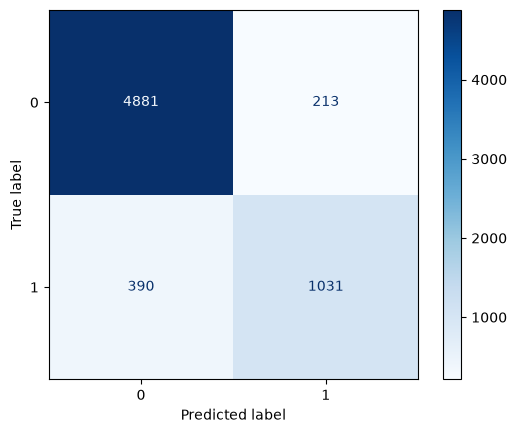

,prevalence,PR-AUC (AP),ROC-AUC,balanced acc,F1 (pos)
Training,0.2182,0.8309,0.8954,0.8493,0.7840
Evaluation,0.2181,0.8146,0.8795,0.8419,0.7737


Set train
              precision    recall  f1-score   support

           0      0.930     0.959     0.944     20373
           1      0.834     0.740     0.784      5686

    accuracy                          0.911     26059
   macro avg      0.882     0.849     0.864     26059
weighted avg      0.909     0.911     0.909     26059

Set test
              precision    recall  f1-score   support

           0      0.926     0.958     0.942      5094
           1      0.829     0.726     0.774      1421

    accuracy                          0.907      6515
   macro avg      0.877     0.842     0.858      6515
weighted avg      0.905     0.907     0.905      6515



In [53]:
# reports for model without knn impute
rows, rep = report(model)
results = pd.DataFrame(rows).T.round(4)
display(results)

for i, z in enumerate(["train", "test"]):
    print(f"Set {z}")
    print(rep[i])

|--- remainder__high_lti_x_rent <= 0.50
|   |--- remainder__loan_grade_sep <= 0.50
|   |   |--- numeric__log_person_income_usd <= 9.90
|   |   |   |--- numeric__loan_to_income_ratio <= 0.15
|   |   |   |   |--- ohe__person_home_ownership_OWN <= 0.50
|   |   |   |   |   |--- weights: [81.86, 82.49] class: 1
|   |   |   |   |--- ohe__person_home_ownership_OWN >  0.50
|   |   |   |   |   |--- weights: [15.99, 0.00] class: 0
|   |   |   |--- numeric__loan_to_income_ratio >  0.15
|   |   |   |   |--- weights: [0.00, 836.40] class: 1
|   |   |--- numeric__log_person_income_usd >  9.90
|   |   |   |--- numeric__log_person_income_usd <= 10.59
|   |   |   |   |--- ohe__loan_intent_HOMEIMPROVEMENT <= 0.50
|   |   |   |   |   |--- weights: [2198.12, 960.14] class: 0
|   |   |   |   |--- ohe__loan_intent_HOMEIMPROVEMENT >  0.50
|   |   |   |   |   |--- weights: [111.28, 295.60] class: 1
|   |   |   |--- numeric__log_person_income_usd >  10.59
|   |   |   |   |--- numeric__lpi_to_lti_ratio <= 0.89


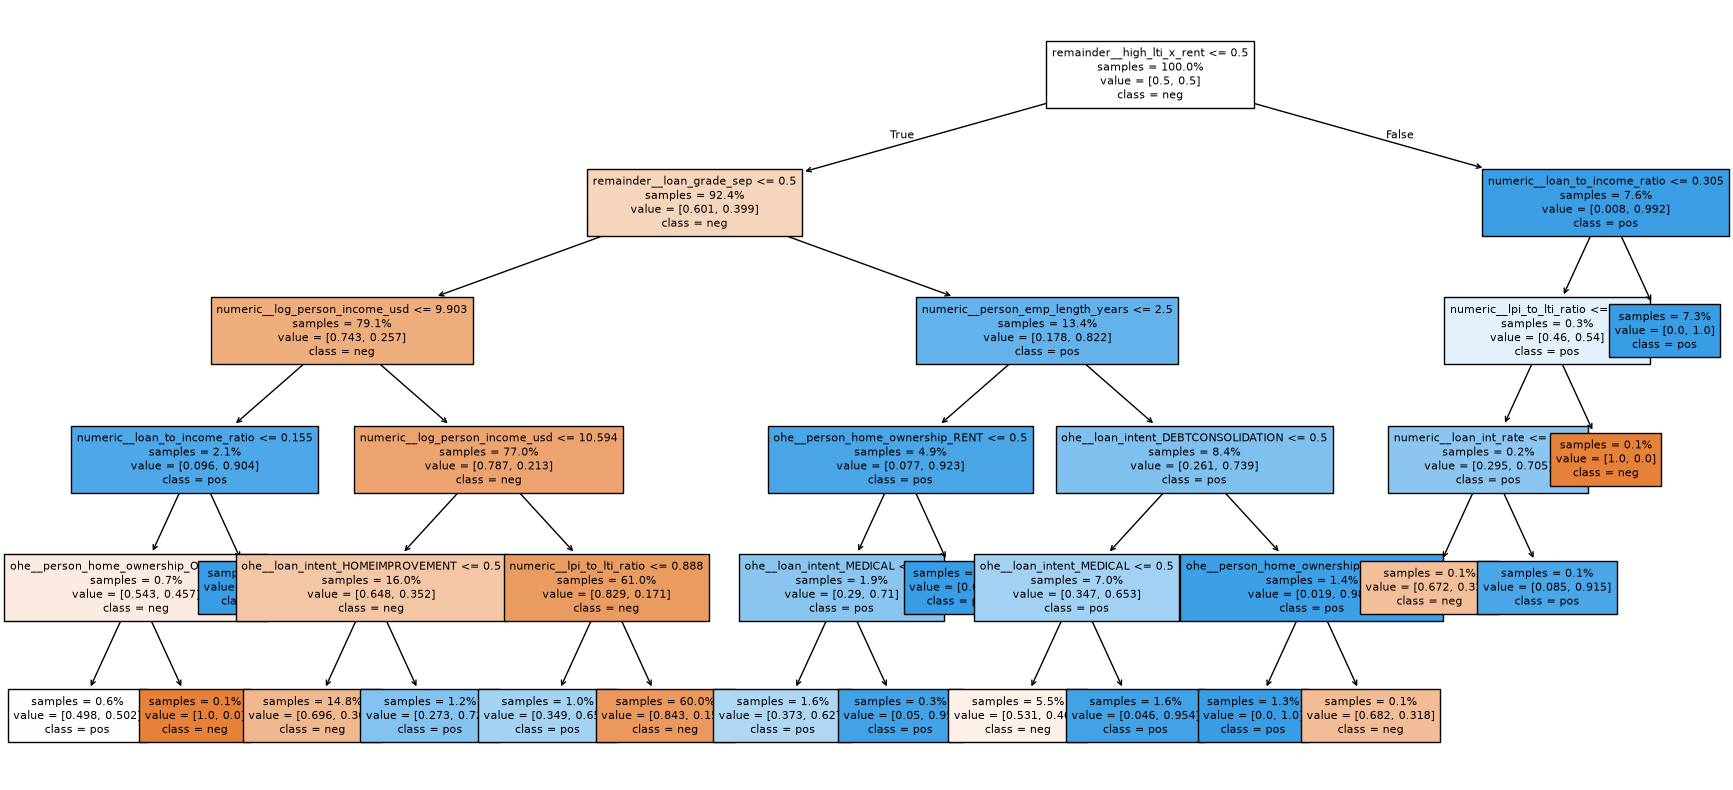

In [54]:
pre = model.named_steps["preprocessor"]
tree = model.named_steps["classifier"]
names = pre.get_feature_names_out()

# Readable rule dump
print(export_text(tree, feature_names=list(names), show_weights=True))

# Plot
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(tree, feature_names=names, class_names=["neg", "pos"],
          filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
plt.show()

In [55]:
# Feature Importance (sum of gains)
print(pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False).head(15))

remainder__loan_grade_sep             0.357322
remainder__high_lti_x_rent            0.354050
numeric__log_person_income_usd        0.149252
ohe__loan_intent_MEDICAL              0.037222
numeric__lpi_to_lti_ratio             0.022477
ohe__loan_intent_HOMEIMPROVEMENT      0.017649
ohe__loan_intent_DEBTCONSOLIDATION    0.017112
numeric__loan_to_income_ratio         0.016344
numeric__person_emp_length_years      0.012554
ohe__person_home_ownership_RENT       0.011069
ohe__person_home_ownership_OWN        0.003681
numeric__loan_int_rate                0.001270
numeric__person_age_years             0.000000
numeric__credit_utilization_ratio     0.000000
numeric__open_accounts                0.000000
dtype: float64


<Axes: >

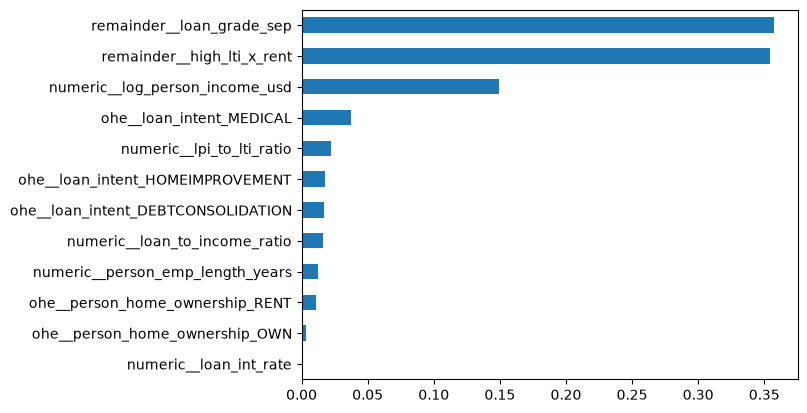

In [64]:
# plot for model
pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False).head(12).sort_values(ascending=True).plot(kind="barh")

<Axes: >

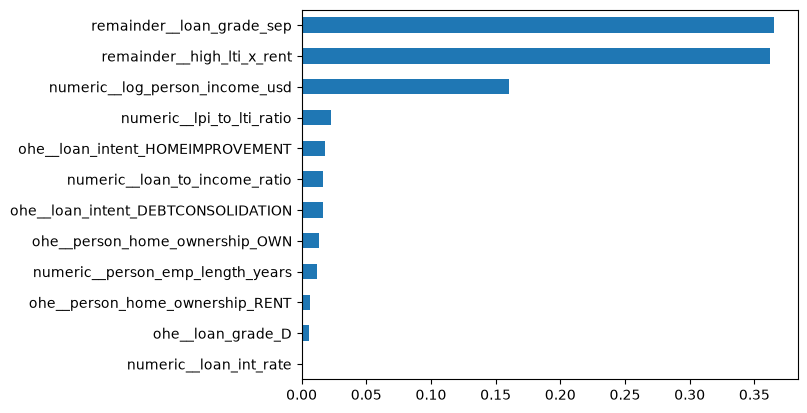

In [65]:
# for impute_model
ipre = impute_model.named_steps["preprocessor"]
itree = impute_model.named_steps["classifier"]
inames = ipre.get_feature_names_out()
pd.Series(itree.feature_importances_, index=inames).sort_values(ascending=False).head(12).sort_values(ascending=True).plot(kind="barh")